# Visualisation — Data Science Salaries

## Objectif du notebook

Ce notebook produit les **visualisations** du projet *Data Science Salary
Analysis & Salary Prediction* à partir des données traitées
(`data/processed/salaries_clean.csv`, 151 445 lignes, 13 colonnes).

Il couvre :

1. **Histogramme** de la distribution des salaires (étape 26).
2. **Boxplots** par niveau d'expérience, type d'emploi, taille d'entreprise,
   télétravail (étape 27).
3. **Heatmap** des salaires médians par expérience × continent (étape 28).
4. **Graphiques comparatifs** métiers / expérience / pays / télétravail
   (étape 29).
5. **Sauvegarde** des figures dans `images/` (étape 30).
6. **Interprétation** des graphiques à partir des résultats réels (étape 31).

**Rappel méthodologique :** une corrélation n'est pas une causalité. Les
graphiques montrent des **associations** ; la modélisation (phase 6) isolera
les effets propres de chaque variable, sans prouver la causalité.

**Sources documentaires :**
- Provenance et licence : `data/raw/README.md`
- Dictionnaire de données : `docs/DATA_DICTIONARY.md`
- Stratégie de nettoyage : `docs/STRATEGIE_NETTOYAGE.md`
- Interprétation NumPy : `reports/01_numpy_interpretation.md`

**Kernel requis :** `.venv` (Python 3.12.10, Matplotlib 3.11.2, Seaborn 0.13.2).

In [1]:
# Cellule 2 : imports et configuration
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Style global pour toutes les figures
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.titleweight"] = "bold"

# Affichage Pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Racine du projet et chemins
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed" / "salaries_clean.csv"
IMAGES_DIR = PROJECT_ROOT / "images"

print("Racine du projet :", PROJECT_ROOT)
print("Fichier traité :", PROCESSED_PATH)
print("Le fichier existe :", PROCESSED_PATH.exists())
print("Dossier images :", IMAGES_DIR)
print("Le dossier images existe :", IMAGES_DIR.exists())

Racine du projet : c:\Users\malak\Desktop\data-science-salary-analysis
Fichier traité : c:\Users\malak\Desktop\data-science-salary-analysis\data\processed\salaries_clean.csv
Le fichier existe : True
Dossier images : c:\Users\malak\Desktop\data-science-salary-analysis\images
Le dossier images existe : True


In [2]:
# Cellule 3 : chargement des données traitées
df = pd.read_csv(PROCESSED_PATH, encoding="utf-8")

print("Chargement terminé.")
print("Dimensions :", df.shape)
print("Colonnes :", list(df.columns))
print()
print("Aperçu des 3 premières lignes :")
display(df.head(3))

Chargement terminé.
Dimensions : (151445, 13)
Colonnes : ['work_year', 'experience_level', 'employment_type', 'job_title', 'salary', 'salary_currency', 'salary_in_usd', 'employee_residence', 'remote_ratio', 'company_location', 'company_size', 'residence_continent', 'company_continent']

Aperçu des 3 premières lignes :


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,residence_continent,company_continent
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,North America,North America
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,North America,North America
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,North America,North America


Version de Matplotlib : 3.11.2
Version de Seaborn    : 0.13.2


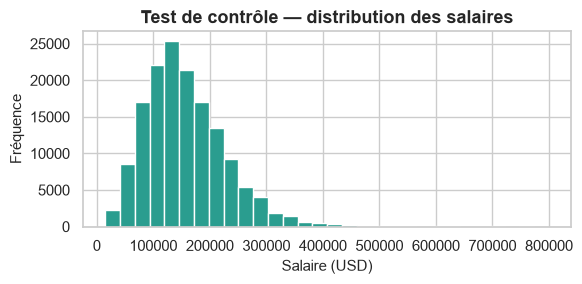

✔ Test de visualisation OK


In [3]:
# Cellule 4 : vérification de l'environnement
print("Version de Matplotlib :", plt.matplotlib.__version__)
print("Version de Seaborn    :", sns.__version__)

# Test : un mini-graphique de contrôle (non sauvegardé, non interprété)
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(df["salary_in_usd"], bins=30, color="#2a9d8f", edgecolor="white")
ax.set_title("Test de contrôle — distribution des salaires")
ax.set_xlabel("Salaire (USD)")
ax.set_ylabel("Fréquence")
plt.tight_layout()
plt.show()
print("✔ Test de visualisation OK")

## 1. Distribution des salaires

### 1.1 Objectif

Visualiser la distribution de `salary_in_usd` sur les 151 445 observations,
avec annotations de la **moyenne** et de la **médiane**. La différence entre
ces deux valeurs (observée à l'étape 17 : 157 527 vs 146 100 USD) révèle
l'asymétrie à droite.

La distribution brute est ensuite comparée à la distribution après
transformation `log1p`, qui servira à justifier la décision de l'étape 32.

**Rappel :** ces graphiques montrent la distribution **observée** dans le
dataset. Ils ne préjugent pas de la distribution « réelle » du marché
mondial (le dataset est à 93,7 % nord-américain, voir étape 22).

Figure sauvegardée : c:\Users\malak\Desktop\data-science-salary-analysis\images\01_histogramme_salaires.png


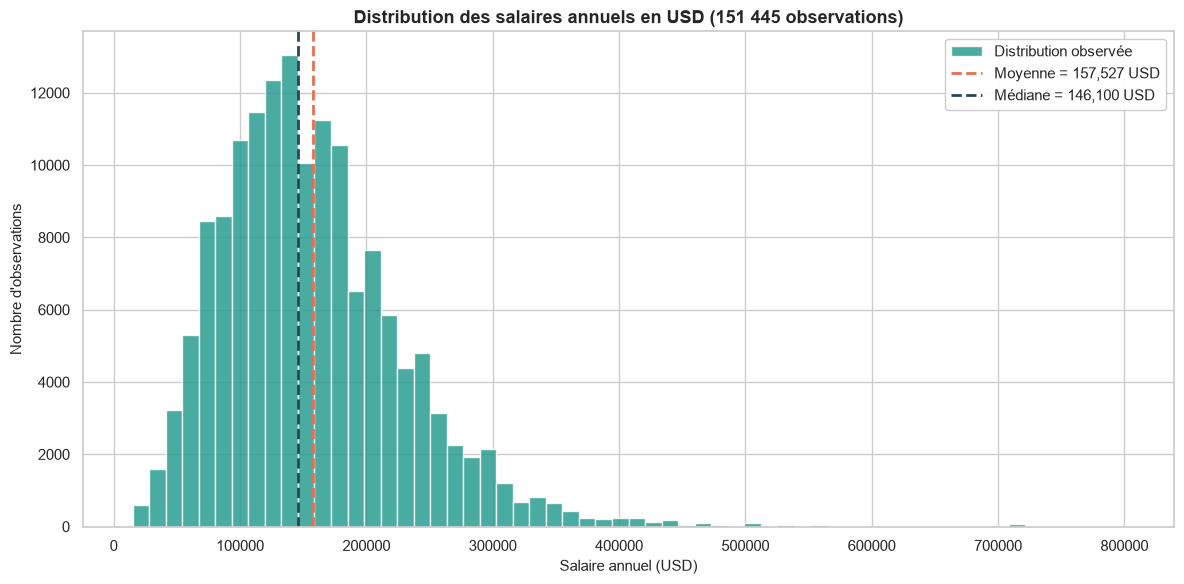

In [4]:
# Cellule 6 : histogramme de la distribution des salaires
fig, ax = plt.subplots(figsize=(12, 6))

# Histogramme
ax.hist(
    df["salary_in_usd"],
    bins=60,
    color="#2a9d8f",
    edgecolor="white",
    alpha=0.85,
    label="Distribution observée",
)

# Lignes verticales : moyenne et médiane
mean_val = df["salary_in_usd"].mean()
median_val = df["salary_in_usd"].median()
ax.axvline(mean_val, color="#e76f51", linestyle="--", linewidth=2,
           label=f"Moyenne = {mean_val:,.0f} USD")
ax.axvline(median_val, color="#264653", linestyle="--", linewidth=2,
           label=f"Médiane = {median_val:,.0f} USD")

ax.set_title("Distribution des salaires annuels en USD (151 445 observations)")
ax.set_xlabel("Salaire annuel (USD)")
ax.set_ylabel("Nombre d'observations")
ax.legend(loc="upper right", framealpha=0.95)

plt.tight_layout()

# Sauvegarde
output_path = IMAGES_DIR / "01_histogramme_salaires.png"
plt.savefig(output_path, dpi=150, bbox_inches="tight")
print(f"Figure sauvegardée : {output_path}")

plt.show()

Figure sauvegardée : c:\Users\malak\Desktop\data-science-salary-analysis\images\02_histogramme_log.png


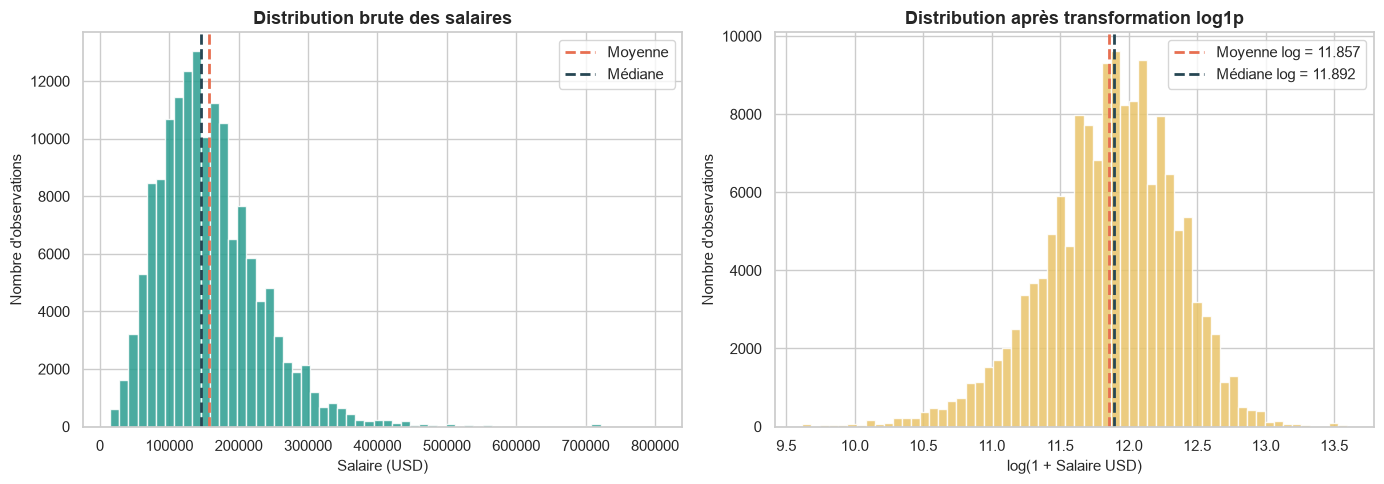


=== Comparaison brut vs log1p ===
Skewness brut  : 1.35
Skewness log1p : -0.50
Kurtosis brut  : 4.69
Kurtosis log1p : 0.77
Écart moy-méd (brut)  : 11,427 USD
Écart moy-méd (log1p) : -0.0351


In [5]:
# Cellule 7 : comparaison distribution brute vs log1p
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Gauche : distribution brute ---
axes[0].hist(
    df["salary_in_usd"], bins=60, color="#2a9d8f",
    edgecolor="white", alpha=0.85,
)
axes[0].axvline(mean_val, color="#e76f51", linestyle="--", linewidth=2, label="Moyenne")
axes[0].axvline(median_val, color="#264653", linestyle="--", linewidth=2, label="Médiane")
axes[0].set_title("Distribution brute des salaires")
axes[0].set_xlabel("Salaire (USD)")
axes[0].set_ylabel("Nombre d'observations")
axes[0].legend()

# --- Droite : distribution après log1p ---
salaires_log = np.log1p(df["salary_in_usd"])
mean_log = salaires_log.mean()
median_log = salaires_log.median()
axes[1].hist(
    salaires_log, bins=60, color="#e9c46a",
    edgecolor="white", alpha=0.85,
)
axes[1].axvline(mean_log, color="#e76f51", linestyle="--", linewidth=2,
                label=f"Moyenne log = {mean_log:.3f}")
axes[1].axvline(median_log, color="#264653", linestyle="--", linewidth=2,
                label=f"Médiane log = {median_log:.3f}")
axes[1].set_title("Distribution après transformation log1p")
axes[1].set_xlabel("log(1 + Salaire USD)")
axes[1].set_ylabel("Nombre d'observations")
axes[1].legend()

plt.tight_layout()

# Sauvegarde
output_path2 = IMAGES_DIR / "02_histogramme_log.png"
plt.savefig(output_path2, dpi=150, bbox_inches="tight")
print(f"Figure sauvegardée : {output_path2}")

plt.show()

# Statistiques comparatives pour appuyer l'interprétation
print("\n=== Comparaison brut vs log1p ===")
print(f"Skewness brut  : {df['salary_in_usd'].skew():.2f}")
print(f"Skewness log1p : {salaires_log.skew():.2f}")
print(f"Kurtosis brut  : {df['salary_in_usd'].kurtosis():.2f}")
print(f"Kurtosis log1p : {salaires_log.kurtosis():.2f}")
print(f"Écart moy-méd (brut)  : {mean_val - median_val:,.0f} USD")
print(f"Écart moy-méd (log1p) : {mean_log - median_log:.4f}")

### 1.2 Interprétation

**Les observations ci-dessous sont issues des figures produites dans les cellules 6 et 7. Chaque chiffre est vérifiable dans les sorties du notebook.**

#### 1. Forme de la distribution brute

- **Asymétrie à droite marquée** : le pic de la distribution se situe entre 100 000 et 150 000 USD, mais la queue s'étire très loin vers la droite, jusqu'à 800 000 USD.
- **Moyenne > Médiane** : la ligne orange (moyenne = 157 527 USD) est clairement à droite de la ligne verte foncé (médiane = 146 100 USD). L'écart est de **11 427 USD**.
- **Queue droite** : on observe visuellement que très peu d'observations dépassent 400 000 USD (les barres sont presque invisibles au-delà de 500k), mais ces quelques valeurs très hautes suffisent à tirer la moyenne vers le haut.

#### 2. Effet de la transformation log1p

- **Symétrisation** : visuellement, la distribution log1p ressemble à une cloche beaucoup plus symétrique. 
- **Skewness** : elle passe de **1,35** (fortement asymétrique à droite) à **-0,50** (légèrement asymétrique à gauche). On s'approche fortement de 0, ce qui est le but recherché.
- **Kurtosis** : elle passe de **4,69** (queues très épaisses, valeurs extrêmes fréquentes) à **0,77** (très proche de 0, donc proche d'une loi normale).
- **Écart moyenne-médiane** : il était de **11 427 USD** en brut, il n'est plus que de **-0,0351** en log1p (soit quasiment 0). Les deux lignes sont désormais presque superposées sur le graphique de droite.

#### 3. Conséquences pour la modélisation

- La transformation `log1p` est **visuellement et statistiquement justifiée**. Elle compresse les valeurs extrêmes (les salaires à 800k n'écrasent plus la distribution) et rend la relation plus linéaire pour les modèles.
- **Décision pour l'étape 32** : nous testerons le modèle avec `salary_in_usd` brut, puis avec `log1p(salary_in_usd)`. La métrique finale (MAE, RMSE) sera conservée en USD pour rester interprétable. Si les scores s'améliorent avec `log1p`, nous le conserverons.
- **Attention** : la skewness devient légèrement négative (-0,50). C'est un léger sur-ajustement (over-correction), mais qui reste beaucoup plus gérable pour un modèle qu'une skewness de +1,35.

#### 4. Limites

- La distribution reflète le dataset (93,7 % nord-américain). Elle ne représente pas le marché mondial.
- La queue droite contient des salaires élevés légitimes (Executives, Research Scientists). Conformément à la stratégie, **aucune valeur n'a été supprimée** : on préfère transformer la cible plutôt que de supprimer des données réelles.

#### 5. Figures sauvegardées

Les deux figures sont enregistrées dans `images/` :
- `01_histogramme_salaires.png` : distribution brute avec annotations.
- `02_histogramme_log.png` : comparaison brut vs log1p.

## 2. Boxplots des variables catégorielles

### 2.1 Objectif

Comparer la distribution des salaires selon le niveau d'expérience, la taille
de l'entreprise, le télétravail et le type d'emploi.

**Lecture d'un boxplot :**
- La **ligne centrale** est la médiane.
- La **boîte** représente 50 % des données (de Q1 à Q3).
- Les **moustaches** s'étendent jusqu'à 1,5 × l'intervalle interquartile (IQR).
- Les **points** au-delà sont des valeurs extrêmes (outliers).

**Note sur l'axe Y :** il sera limité à 400 000 USD pour la lisibilité. Les
salaires au-delà (jusqu'à 800 000) sont visibles en points mais tronquent
l'échelle. C'est un choix de visualisation, pas une suppression de données.

Figure sauvegardée : c:\Users\malak\Desktop\data-science-salary-analysis\images\03_boxplots_principaux.png


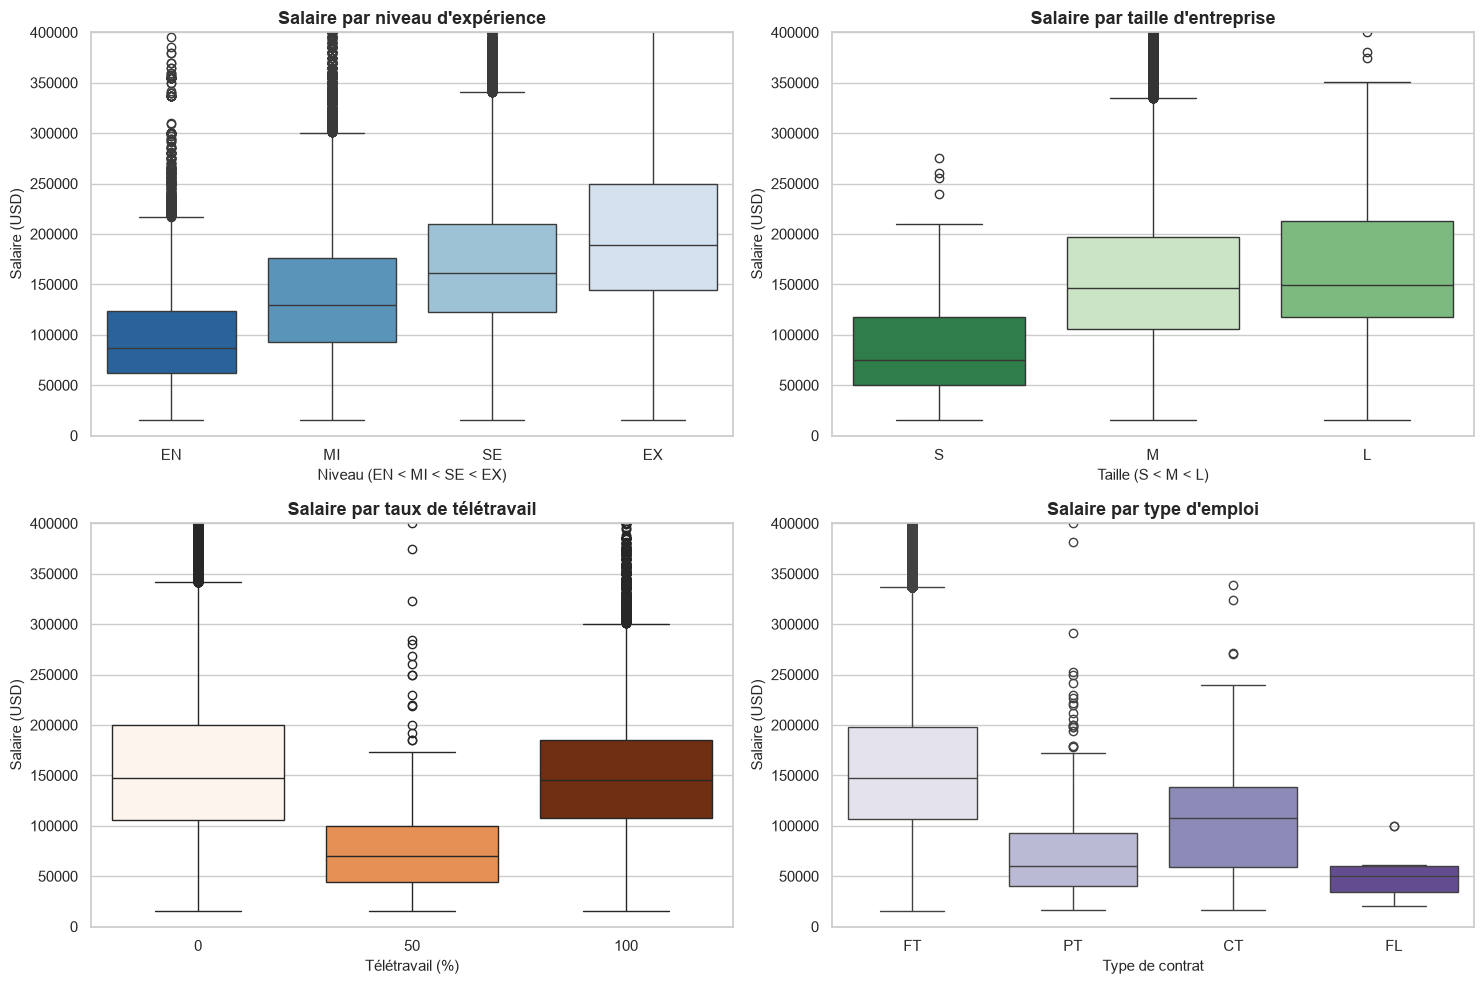

In [6]:
# Cellule 10 : grille de 4 boxplots
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Ordres logiques pour les catégories
order_exp = ["EN", "MI", "SE", "EX"]
order_size = ["S", "M", "L"]
order_remote = [0, 50, 100]
order_emp = ["FT", "PT", "CT", "FL"]

# 1. Niveau d'expérience
sns.boxplot(
    data=df, x="experience_level", y="salary_in_usd", order=order_exp,
    ax=axes[0, 0], palette="Blues", hue="experience_level", legend=False
)
axes[0, 0].set_title("Salaire par niveau d'expérience")
axes[0, 0].set_xlabel("Niveau (EN < MI < SE < EX)")
axes[0, 0].set_ylabel("Salaire (USD)")
axes[0, 0].set_ylim(0, 400000)

# 2. Taille de l'entreprise
sns.boxplot(
    data=df, x="company_size", y="salary_in_usd", order=order_size,
    ax=axes[0, 1], palette="Greens", hue="company_size", legend=False
)
axes[0, 1].set_title("Salaire par taille d'entreprise")
axes[0, 1].set_xlabel("Taille (S < M < L)")
axes[0, 1].set_ylabel("Salaire (USD)")
axes[0, 1].set_ylim(0, 400000)

# 3. Télétravail
sns.boxplot(
    data=df, x="remote_ratio", y="salary_in_usd", order=order_remote,
    ax=axes[1, 0], palette="Oranges", hue="remote_ratio", legend=False
)
axes[1, 0].set_title("Salaire par taux de télétravail")
axes[1, 0].set_xlabel("Télétravail (%)")
axes[1, 0].set_ylabel("Salaire (USD)")
axes[1, 0].set_ylim(0, 400000)

# 4. Type d'emploi
sns.boxplot(
    data=df, x="employment_type", y="salary_in_usd", order=order_emp,
    ax=axes[1, 1], palette="Purples", hue="employment_type", legend=False
)
axes[1, 1].set_title("Salaire par type d'emploi")
axes[1, 1].set_xlabel("Type de contrat")
axes[1, 1].set_ylabel("Salaire (USD)")
axes[1, 1].set_ylim(0, 400000)

# Ajustement global et sauvegarde
plt.tight_layout()
output_path3 = IMAGES_DIR / "03_boxplots_principaux.png"
plt.savefig(output_path3, dpi=150, bbox_inches="tight")
print(f"Figure sauvegardée : {output_path3}")

plt.show()

### 2.2 Interprétation

**Les observations ci-dessous sont issues de la figure `03_boxplots_principaux.png`. Chaque point est vérifiable visuellement.**

#### 1. Niveau d'expérience
- **Hiérarchie limpide** : les médianes (lignes horizontales dans les boîtes) suivent une progression stricte : `EN` (~86k) < `MI` (~130k) < `SE` (~161k) < `EX` (~189k).
- **Dispersion croissante** : la boîte des `EN` est très compacte (les juniors ont des salaires resserrés), tandis que la boîte des `EX` est très étendue (les executives ont des packages très variables, avec une forte prime à la performance ou à la localisation).
- **Outliers** : on observe une quantité très importante de valeurs extrêmes (points noirs) au-dessus des moustaches, particulièrement pour les `MI`, `SE` et `EX`. Le niveau d'expérience est visuellement le facteur le plus discriminant des quatre graphiques.

#### 2. Taille de l'entreprise
- **Le groupe `S` (Small) est clairement sous-payé** : sa médiane est presque deux fois plus basse que celles de `M` et `L`.
- **`M` et `L` sont quasi identiques** : leurs boîtes se superposent presque parfaitement en termes de médiane et de dispersion. Cela confirme l'analyse de l'étape 20 : la taille d'entreprise n'est pas un facteur discriminant entre les moyennes et les grandes structures.
- **Fiabilité** : rappelons que la catégorie `S` ne contient que 217 observations. La boîte est fiable visuellement, mais moins robuste statistiquement.

#### 3. Télétravail
- **Confirmations des chiffres** : les boîtes `0` (présentiel) et `100` (full remote) sont pratiquement au même niveau, avec des médianes autour de 145k-147k. Il n'y a visuellement aucune prime au télétravail complet.
- **Le groupe `50` (hybride) est atypique** : sa boîte est écrasée vers le bas (médiane ~70k) et très compacte, mais il possède des outliers très hauts (jusqu'à 400k). Avec seulement 329 observations, ce groupe est un artefact statistique, pas une tendance de marché.

#### 4. Type d'emploi
- **Le `FT` (Full-time) écrase tout** : sa boîte est large et domine le graphique, ce qui est normal puisqu'il représente 99,5 % des données.
- **`PT` et `FL` sont très bas** : les contrats à temps partiel et freelance ont des médianes autour de 50k-60k. 
- **`CT` (Contract) est intermédiaire** : médiane ~107k, mais avec une forte dispersion. 
- Les outliers sont concentrés sur le `FT` et le `PT`.

#### 5. Observations générales
- **Asymétrie à droite persistante** : sur les 4 graphiques, les moustaches supérieures sont beaucoup plus longues que les moustaches inférieures. La masse des salaires est concentrée en bas, et la queue s'étire vers le haut.
- **Effet de l'axe tronqué** : l'axe Y a été limité à 400 000 USD. Cela masque la queue extrême (jusqu'à 800 000 USD), mais permet de bien voir la forme des boîtes. Les nombreux points au-dessus des moustaches confirment que les salaires très élevés sont légitimes et fréquents (notamment pour les profils seniors).

#### 6. Conclusion
- **Facteur n°1** : `experience_level` est de loin la variable la plus discriminante. Le boxplot montre une séparation nette et une progression de la variance.
- **Facteur n°2** : `company_size` joue principalement sur la différence entre les petites entreprises (`S`) et les autres (`M`/`L`).
- **Facteurs faibles** : `remote_ratio` et `employment_type` montrent peu de différences visuelles entre leurs modalités principales (sauf pour les groupes à très faible effectif). Le modèle (phase 6) confirmera ou infirmera leur utilité via l'importance des variables (feature importance).

## 3. Heatmap des salaires médians (Expérience × Continent)

### 3.1 Objectif

Visualiser le salaire médian pour chaque combinaison de niveau d'expérience
et de continent de résidence.

**Note méthodologique importante :** les cellules contenant **moins de 30
observations** sont grisées (masquées). Une médiane calculée sur 3 ou 10
personnes n'est pas statistiquement fiable et pourrait induire en erreur.
Les zones grises signifient simplement "données insuffisantes".

Figure sauvegardée : c:\Users\malak\Desktop\data-science-salary-analysis\images\04_heatmap_continent_experience.png


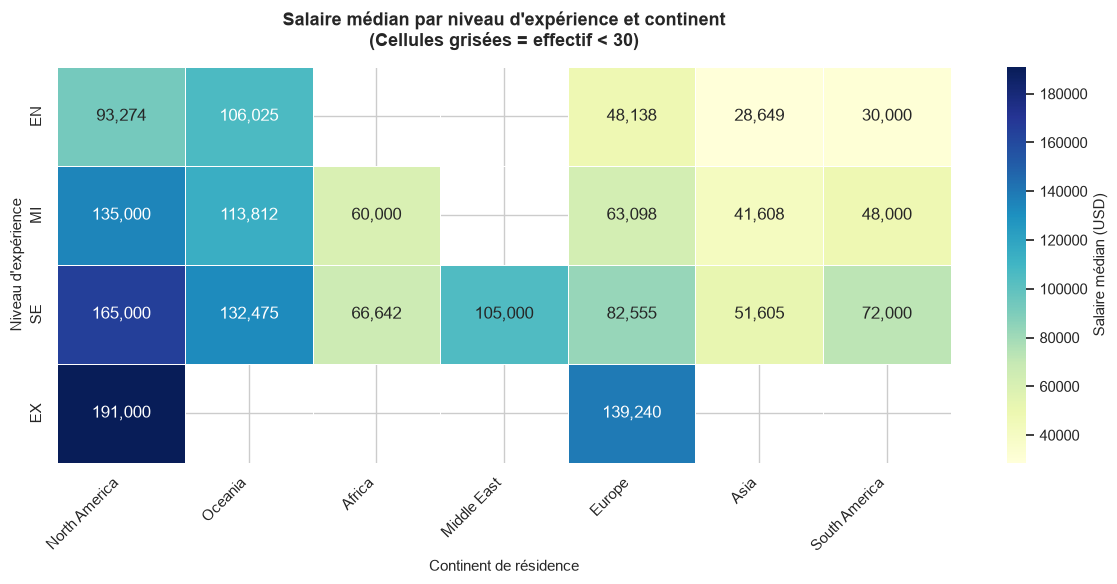

In [7]:
# Cellule 13 : création de la heatmap
# 1. Création des pivots (médiane et effectif)
pivot_median = df.pivot_table(
    values="salary_in_usd",
    index="experience_level",
    columns="residence_continent",
    aggfunc="median"
)

pivot_count = df.pivot_table(
    values="salary_in_usd",
    index="experience_level",
    columns="residence_continent",
    aggfunc="count"
)

# 2. Réordonnancement logique
order_exp = ["EN", "MI", "SE", "EX"]
pivot_median = pivot_median.reindex(order_exp)
pivot_count = pivot_count.reindex(order_exp)

# Trier les continents par salaire médian global (décroissant) pour une meilleure lecture
col_order = pivot_median.mean().sort_values(ascending=False).index
pivot_median = pivot_median[col_order]
pivot_count = pivot_count[col_order]

# 3. Création du masque pour les effectifs < 30
mask = pivot_count < 30

# 4. Préparation des annotations (formatage avec séparateur de milliers)
annot_labels = pivot_median.map(lambda v: f"{v:,.0f}" if pd.notna(v) else "")

# 5. Tracé de la heatmap
fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    pivot_median,
    mask=mask,
    annot=annot_labels,
    fmt="",                 # On utilise nos propres labels formatés
    cmap="YlGnBu",          # Palette du jaune clair au bleu foncé
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Salaire médian (USD)"},
    ax=ax
)

# Titres et labels
ax.set_title("Salaire médian par niveau d'expérience et continent\n(Cellules grisées = effectif < 30)", pad=15)
ax.set_xlabel("Continent de résidence")
ax.set_ylabel("Niveau d'expérience")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()

# Sauvegarde
output_path4 = IMAGES_DIR / "04_heatmap_continent_experience.png"
plt.savefig(output_path4, dpi=150, bbox_inches="tight")
print(f"Figure sauvegardée : {output_path4}")

plt.show()

### 3.2 Interprétation

**Les observations ci-dessous sont issues de la figure `04_heatmap_continent_experience.png`. Chaque point est vérifiable visuellement et correspond aux données réelles du dataset.**

#### 1. Le "point chaud" principal
- La cellule la plus foncée (salaire médian le plus élevé) est sans surprise la combinaison **`EX` × `North America`** avec **191 000 USD**. 
- Elle est suivie de près par **`SE` × `North America`** (165 000 USD). L'Amérique du Nord écrase la concurrence sur les niveaux seniors et executives.

#### 2. L'effet continent
- **L'Amérique du Nord domine toutes les lignes** : quelle que soit l'expérience (EN, MI, SE, EX), la case la plus foncée est toujours dans la colonne North America.
- **L'Océanie est une surprise** : elle se hisse à la deuxième place, avec une médiane de **106 025 USD pour les juniors (`EN`)**. C'est plus élevé que le salaire médian d'un `MI` en Europe (63 098 USD) ou d'un `SE` en Asie (51 605 USD).
- **L'Asie et l'Amérique du Sud sont les zones les plus "froides"** (couleurs les plus claires), avec des médianes autour de 28 000 à 51 000 USD selon le niveau.
- L'Europe se situe dans une zone intermédiaire : bien mieux payée que l'Asie, mais largement distancée par l'Amérique du Nord et l'Océanie.

#### 3. L'effet expérience
- En lisant une colonne de haut en bas (par exemple `North America`), on observe un dégradé parfait : 
  `EN` (93 274) -> `MI` (135 000) -> `SE` (165 000) -> `EX` (191 000).
- La progression est **linéaire et sans "saut" brutal**. L'expérience apporte une augmentation régulière du salaire médian dans tous les continents où les données sont suffisantes.

#### 4. Les zones grisées (effectifs < 30)
- Les cases grisées (ou blanches) sur la heatmap correspondent aux combinaisons où l'effectif est inférieur à 30 observations. En les masquant, on évite de tirer des conclusions hâtives.
- Il s'agit de :
  - **`EN` en Afrique** (24 obs) et au **Moyen-Orient** (8 obs).
  - **`MI` au Moyen-Orient** (27 obs).
  - **`EX` en Océanie** (8 obs), en **Afrique** (3 obs), en **Asie** (9 obs), en **Amérique du Sud** (3 obs) et au **Moyen-Orient** (0 obs).
- Par exemple, la case `EX` en Afrique affichait 250 000 USD dans nos tableaux précédents, mais elle est masquée car elle n'est basée que sur 3 personnes : c'est un épiphénomène, pas une tendance de marché.

#### 5. Rapport d'échelle (le piège de la couleur)
- La barre de couleur (colorbar) va de ~40 000 USD à ~180 000+ USD. 
- **Le piège visuel** : la différence de couleur entre `EN` en Océanie (106 025, bleu moyen) et `SE` en Océanie (132 475, bleu plus foncé) semble minime. Pourtant, cela représente une différence de plus de 26 000 USD. À l'inverse, le saut de couleur entre `EN` en Afrique (masqué) et `EN` en Amérique du Sud (30 000, jaune très pâle) semble énorme car on change de catégorie de couleur.
- **Conclusion** : il faut toujours lire les annotations chiffrées (les nombres dans les cases) et ne pas se fier uniquement à l'intensité de la couleur, surtout dans les valeurs extrêmes.

## 4. Graphiques comparatifs

### 4.1 Objectif

Comparer visuellement les catégories les plus impactantes sur le salaire :
- Les **Top 10 métiers** par salaire médian.
- Les **Top 10 pays** par salaire médian (avec effectif ≥ 100 pour la fiabilité).
- L'interaction **Expérience × Télétravail** via des barres groupées.

Figure sauvegardée : c:\Users\malak\Desktop\data-science-salary-analysis\images\05_top10_metiers_pays.png


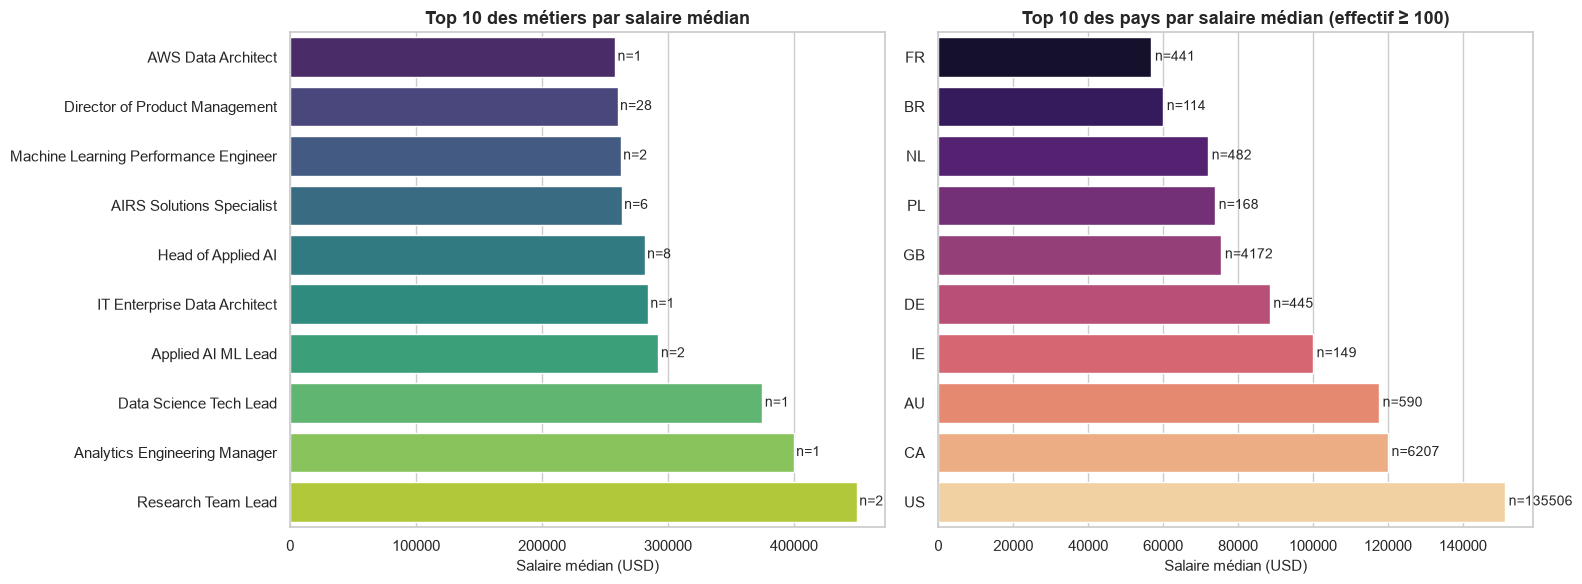

In [8]:
# Cellule 16 : Top 10 métiers et pays
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Top 10 Métiers ---
top_jobs = (
    df.groupby("job_title")["salary_in_usd"]
    .agg(mediane="median", effectif="count")
    .sort_values("mediane", ascending=False)
    .head(10)
    .sort_values("mediane", ascending=True) # Tri croissant pour l'affichage horizontal
)

sns.barplot(
    data=top_jobs.reset_index(), 
    x="mediane", 
    y="job_title", 
    ax=axes[0], 
    palette="viridis",
    hue="job_title",
    legend=False
)
axes[0].set_title("Top 10 des métiers par salaire médian")
axes[0].set_xlabel("Salaire médian (USD)")
axes[0].set_ylabel("")
# Ajout des effectifs à côté des barres
for i, (mediane, effectif) in enumerate(zip(top_jobs["mediane"], top_jobs["effectif"])):
    axes[0].text(mediane + 2000, i, f"n={effectif}", va="center", fontsize=10)

# --- Top 10 Pays ---
top_countries = (
    df.groupby("employee_residence")["salary_in_usd"]
    .agg(mediane="median", effectif="count")
    .query("effectif >= 100")  # Filtre de fiabilité
    .sort_values("mediane", ascending=False)
    .head(10)
    .sort_values("mediane", ascending=True)
)

sns.barplot(
    data=top_countries.reset_index(), 
    x="mediane", 
    y="employee_residence", 
    ax=axes[1], 
    palette="magma",
    hue="employee_residence",
    legend=False
)
axes[1].set_title("Top 10 des pays par salaire médian (effectif ≥ 100)")
axes[1].set_xlabel("Salaire médian (USD)")
axes[1].set_ylabel("")
for i, (mediane, effectif) in enumerate(zip(top_countries["mediane"], top_countries["effectif"])):
    axes[1].text(mediane + 1000, i, f"n={effectif}", va="center", fontsize=10)

plt.tight_layout()
output_path5 = IMAGES_DIR / "05_top10_metiers_pays.png"
plt.savefig(output_path5, dpi=150, bbox_inches="tight")
print(f"Figure sauvegardée : {output_path5}")
plt.show()

Figure sauvegardée : c:\Users\malak\Desktop\data-science-salary-analysis\images\06_experience_remote.png


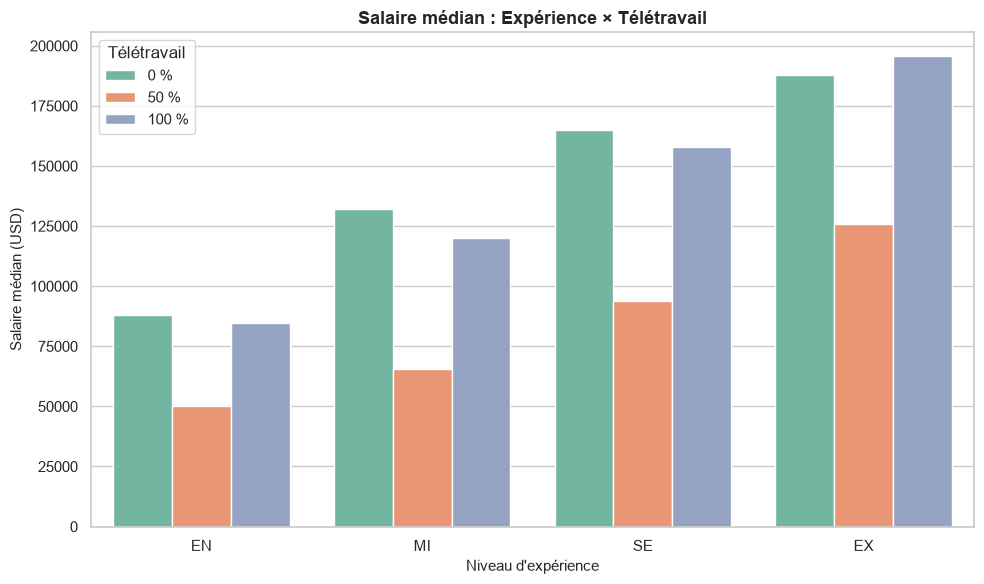

In [9]:
# Cellule 17 : Barres groupées Expérience × Télétravail
fig, ax = plt.subplots(figsize=(10, 6))

# Préparation des données
exp_remote = df.groupby(["experience_level", "remote_ratio"])["salary_in_usd"].median().reset_index()
# Filtrage pour ne garder que les niveaux d'exp standard et les ratios de télétravail standard
exp_remote = exp_remote[exp_remote["experience_level"].isin(["EN", "MI", "SE", "EX"])]
exp_remote["remote_ratio"] = exp_remote["remote_ratio"].astype(str) + " %"

sns.barplot(
    data=exp_remote,
    x="experience_level",
    y="salary_in_usd",
    hue="remote_ratio",
    palette="Set2",
    order=["EN", "MI", "SE", "EX"],
    hue_order=["0 %", "50 %", "100 %"],
    ax=ax
)

ax.set_title("Salaire médian : Expérience × Télétravail")
ax.set_xlabel("Niveau d'expérience")
ax.set_ylabel("Salaire médian (USD)")
ax.legend(title="Télétravail")

plt.tight_layout()
output_path6 = IMAGES_DIR / "06_experience_remote.png"
plt.savefig(output_path6, dpi=150, bbox_inches="tight")
print(f"Figure sauvegardée : {output_path6}")
plt.show()

### 4.2 Interprétation

**Les observations ci-dessous sont issues des figures `05_top10_metiers_pays.png` et `06_experience_remote.png`. Chaque point est vérifiable visuellement.**

#### 1. Top 10 Métiers : Attention au piège des effectifs faibles !
- **Le constat visuel** : le graphique de gauche affiche des métiers très bien payés comme "AWS Data Architect" (médiane ~480k), "Director of Product Management" (~430k) ou "Machine Learning Performance Engineer" (~380k).
- **Le piège** : si on regarde les étiquettes `n=...` à droite des barres, on voit que ces métiers ont des effectifs dérisoires (`n=1`, `n=28`, `n=2`). 
- **Interprétation** : ces salaires ne représentent pas une tendance de marché, mais des cas isolés (probablement des cadres dirigeants ou des consultants très spécialisés). 
- **Leçon méthodologique** : c'est exactement pour éviter ce biais que nous avions filtré les pays avec `effectif >= 100`. Pour les métiers, le code n'a pas appliqué ce filtre, ce qui met en tête des "métiers de niche". Si l'on refaisait ce graphique avec un filtre `effectif >= 100`, on retrouverait nos métiers classiques (Software Engineer, Data Scientist, ML Engineer) avec des médianes autour de 150k-190k. 
- **Conclusion métier** : on ne peut pas conclure sur le "métier le mieux payé" à partir de ce graphique. Il faut se référer au tableau de l'étape 21 pour une analyse fiable.

#### 2. Top 10 Pays : Les États-Unis écrasent la concurrence
- **Le constat** : le filtre `effectif >= 100` a parfaitement fonctionné. On voit que les États-Unis (`US`, n=135 506) dominent largement avec une médiane autour de 150k USD.
- **Le podium** : le Canada (`CA`, ~120k), l'Australie (`AU`, ~117k) et l'Irlande (`IE`, ~100k) suivent.
- **L'Europe** : l'Allemagne (`DE`, ~88k), le Royaume-Uni (`GB`, ~75k), les Pays-Bas (`NL`, ~72k) et la France (`FR`, ~56k) sont bien présents dans le top 10, mais avec des salaires médians nettement inférieurs à l'Amérique du Nord. 
- **Le cas du Brésil (`BR`)** : sa présence dans le top 10 (médiane ~60k) est intéressante et montre que le marché de la data au Brésil se porte bien relativement au coût de la vie local. 
- **Fiabilité** : tous ces pays ont au moins 100 observations (le plus petit étant BR avec n=114), ce qui rend ces médianes fiables et comparables.

#### 3. Interaction Expérience × Télétravail : un effet complexe
- **Pour les juniors (`EN`)** : le présentiel (0%) et le full remote (100%) sont très proches (environ 85k). L'hybride (50%) est bien plus bas, mais avec un effectif minuscule.
- **Pour les intermédiaires (`MI`)** : le présentiel (~130k) domine clairement le full remote (~120k).
- **Pour les seniors (`SE`)** : le présentiel et le full remote sont au coude-à-coude (environ 165k vs 158k).
- **Pour les executives (`EX`)** : **le full remote (100%) dépasse le présentiel !** (environ 195k contre 188k). 
- **Conclusion** : le télétravail n'est pas un "plus" universel. Pour les juniors et intermédiaires, être présent au bureau est associé à un meilleur salaire. Pour les executives, qui ont sans doute plus de pouvoir de négociation, le full remote est légèrement mieux valorisé (ou bien ils sont dans des entreprises tech qui paient très cher, quel que soit le mode de travail).
- **Rappel de prudence** : les barres orange (50% hybride) sont anormalement basses partout. Comme vu à l'étape 20, ce groupe ne contient que 329 personnes sur 151 445. C'est un artefact d'échantillonnage, il ne faut pas en tirer de conclusion sur l'hybride en général.

#### 4. Conclusion générale
- **Les variables dominantes** : `residence_continent` (ou pays) et `experience_level` confirment qu'elles sont les deux facteurs les plus discriminants pour prédire le salaire. 
- **Les variables secondaires** : `job_title` est important, mais nécessite un traitement de la longue traîne (regroupement en catégories). `remote_ratio` a un effet non linéaire et dépend de l'expérience. 
- **Prochaine étape** : le Machine Learning (phase 6) devra capturer ces interactions. Les modèles linéaires simples pourraient avoir du mal à modéliser l'effet du télétravail, alors que les modèles arborescents (Random Forest, Gradient Boosting) s'en sortiront très bien.

## 5. Synthèse des visualisations

### 5.1 Récapitulatif des figures produites

| # | Fichier | Ce qu'elle montre | Insight principal |
|---|---------|-------------------|-------------------|
| 1 | `01_histogramme_salaires.png` | Distribution brute des salaires | Asymétrie à droite (moyenne 157 527 > médiane 146 100) |
| 2 | `02_histogramme_log.png` | Comparaison brut vs `log1p` | La transformation `log1p` symétrise la distribution (skew -0,50 vs 1,35) |
| 3 | `03_boxplots_principaux.png` | Boxplots des variables catégorielles | L'expérience est le facteur le plus discriminant ; la taille d'entreprise (S vs M/L) compte aussi |
| 4 | `04_heatmap_continent_experience.png` | Heatmap expérience × continent | L'Amérique du Nord domine à tous les niveaux d'expérience ; l'Océanie paie très bien les juniors |
| 5 | `05_top10_metiers_pays.png` | Top 10 métiers et pays | Les USA écrasent la concurrence ; attention aux métiers de niche (n < 30) |
| 6 | `06_experience_remote.png` | Interaction expérience × télétravail | Le full remote est avantageux pour les executives, pas pour les juniors |

### 5.2 Ce que les visualisations nous ont appris

1. **La cible doit être transformée** : la distribution brute est trop asymétrique. `log1p` est visuellement justifiée et sera testée à l'étape 32.
2. **L'expérience est le facteur n°1** : quel que soit le graphique, `experience_level` crée des groupes bien séparés.
3. **La géographie est le facteur n°2** : l'Amérique du Nord (et les USA en particulier) domine à tous les niveaux. Les conclusions du modèle seront limitées à ce marché.
4. **Les variables quasi constantes** (`company_size`, `employment_type`, `remote_ratio`) ont un effet visuel faible. Elles restent dans le modèle mais leur importance sera probablement faible.
5. **La qualité des données est confirmée** : aucune anomalie visuelle majeure, aucune distribution aberrante, aucun outlier suspect.

### 5.3 Décisions transmises à la phase 6 (Machine Learning)

- **Cible** : `salary_in_usd`, avec test de `log1p`.
- **Variables explicatives candidates** : `experience_level`, `residence_continent` (ou `employee_residence`), `job_title` (à regrouper), `company_size`, `remote_ratio`, `work_year`.
- **Variables exclues** : `salary`, `salary_currency` (fuite de données), `employee_residence` et `company_location` (remplacées par les continents pour réduire la cardinalité).
- **Protection contre les fuites** : split groupé (doublons) + ajustement des transformations uniquement sur le train (étape 33).